<a href="https://colab.research.google.com/github/sanjanatadmeri/TSANJANA4IK25CS221/blob/main/4IK25CS221_LAB7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error

In [ ]:
df=pd.read_csv('/content/Titanic-Dataset.csv')
df=df[['Fare','Pclass','Age','SibSp','Parch']]
df['Age']=df['Age'].fillna(df['Age'].median())
df=df[df['Fare']>0]

In [ ]:
X_sample=df[['Pclass']]
y=df['Fare']
X_tr,X_te,y_tr,y_te=train_test_split(X_sample,y,test_size=0.2,random_state=42)
model_simple=LinearRegression().fit(X_tr,y_tr)
pred_simple=model_simple.predict(X_te)
print('SIMPLE REGRESSION--INTERCEPT:',round(model_simple.intercept_,2))
print('SIMPLE REGRESSION--SLOPE:',round(model_simple.coef_[0],2))
print('SIMPLE REGRESSION--R2:',round(round(r2_score(y_te,pred_simple),3)))
print('SIMPLE REGRESSION--RMSE:',round(np.sqrt(mean_squared_error(y_te,pred_simple)),2))

SIMPLE REGRESSION--INTERCEPT: 112.38
SIMPLE REGRESSION--SLOPE: -34.23
SIMPLE REGRESSION--R2: 0
SIMPLE REGRESSION--RMSE: 35.68


In [ ]:
X_multi=df[['Pclass','Age','SibSp','Parch']]
X_tr2,X_te2,y_tr2,y_te2=train_test_split(X_multi,y,test_size=0.2,random_state=42)
model_multi=LinearRegression().fit(X_tr2,y_tr2)
pred_multi=model_multi.predict(X_te2)
print('\nMultiple regression -- intercept:',round(model_multi.intercept_,2))
for name, coef in zip(X_multi.columns,model_multi.coef_):
  print('Multiple regression -- coefficient of',name,':',round(coef,2))
print('Multiple regression -- R2:',round(r2_score(y_te,pred_simple),3))
print('SIMPLE REGRESSION--RMSE:',round(np.sqrt(mean_squared_error(y_te,pred_simple)),2))


Multiple regression -- intercept: 112.3
Multiple regression -- coefficient of Pclass : -35.72
Multiple regression -- coefficient of Age : -0.12
Multiple regression -- coefficient of SibSp : 5.38
Multiple regression -- coefficient of Parch : 10.09
Multiple regression -- R2: 0.371
SIMPLE REGRESSION--RMSE: 35.68


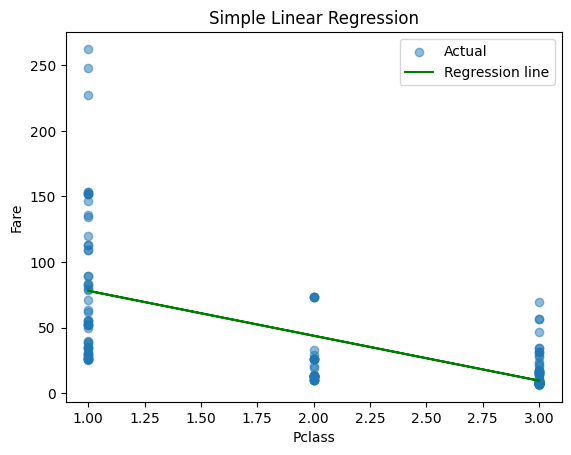

In [ ]:
plt.scatter(X_te,y_te,alpha=0.5,label='Actual')
plt.plot(X_te,pred_simple,color='green',label='Regression line')
plt.xlabel('Pclass')
plt.ylabel('Fare')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

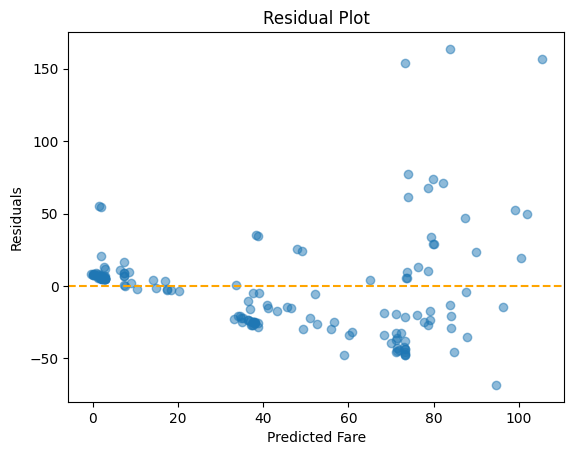

In [ ]:
residuals=y_te2-pred_multi
plt.scatter(pred_multi,residuals,alpha=0.5)
plt.axhline(0,color='orange',linestyle='--')
plt.xlabel('Predicted Fare')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

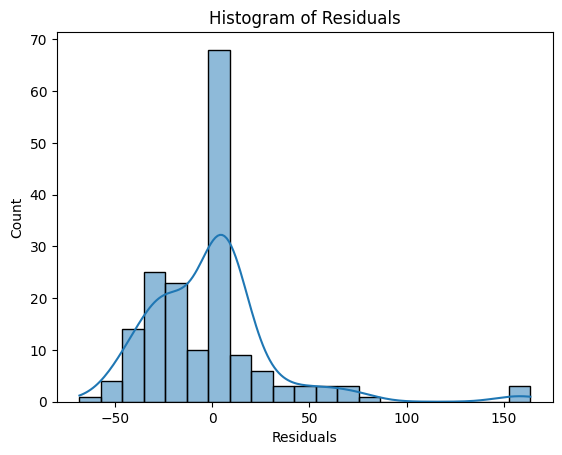

In [ ]:
sns.histplot(residuals,kde=True)
plt.xlabel('Residuals')
plt.title('Histogram of Residuals')
plt.show()


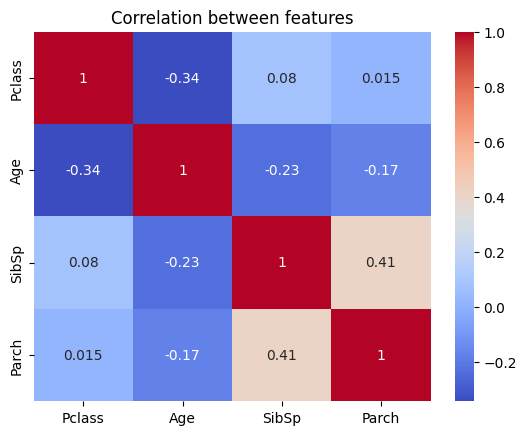

In [ ]:
sns.heatmap(X_multi.corr(),annot=True,cmap='coolwarm')
plt.title('Correlation between features')
plt.show()